# Bioreactor analysis — a guided restart

Work from top to bottom. Each section asks one question and produces one useful result. This notebook deliberately avoids ODEs and complicated models.

**Goal:** understand the observations, understand the feed events, then test one simple prediction baseline on unseen batches.

The working target is the four missing biological variables. Confirm the official target columns, units, metric, and allowed inputs with the organizers. We use recorded units rather than guessing hours, days, liters, or metabolite identities.

## 1. Load the data
Put the CSV beside this notebook, or change `DATA_PATH` below. Imports and configuration belong in this first cell. All other cells depend on it.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("/home/renku/work/input-data/Project 1 - DTB/bioreaction_remaining.csv")
TARGETS = ["vcd", "tcd", "substrate", "byproduct"]
FEEDS = ["feed_substrate", "feed_b", "feed_c", "feed_d"]
df = pd.read_csv(DATA_PATH).sort_values(
    ["batch_id", "elapsed_time"], kind="stable"
).reset_index(drop=True)
print(f"{len(df):,} rows | {df.batch_id.nunique()} batches")
print(df.head(6).to_string(index=False))

2,858 rows | 61 batches
batch_id  elapsed_time      vcd      tcd  substrate  byproduct  feed_substrate   feed_b   feed_c  feed_d    volume  to_predict
  Batch1      0.000000 0.979690 0.985251   4.507188   0.241840             NaN      NaN      NaN     NaN 10.500750       False
  Batch1      0.996528 1.909271 1.929805   3.830345   0.940785             NaN      NaN      NaN     NaN 10.494285       False
  Batch1      1.014977      NaN      NaN        NaN        NaN             NaN 0.062214      NaN     NaN       NaN       False
  Batch1      1.984722 4.574543 4.611517   2.827742   1.860896             NaN      NaN      NaN     NaN 10.537027       False
  Batch1      2.044421      NaN      NaN        NaN        NaN             NaN 0.136099      NaN     NaN       NaN       False
  Batch1      2.722998      NaN      NaN        NaN        NaN             NaN      NaN 0.000854     NaN       NaN       False


### Read the result
A row is an event, not necessarily a complete measurement. A blank biological value on a feed row means *not measured*, not zero.

## 2. Separate the three row types
We give three names to things:
- `observations`: rows with all four biological measurements.
- `feed_events`: rows recording an addition.
- `prediction_rows`: requested times where biological measurements are hidden.

This does not fill missing values or invent observations.

In [27]:
observed_mask = df[TARGETS].notna().all(axis=1)
feed_mask = df[FEEDS].notna().any(axis=1)
prediction_mask = df["to_predict"].eq(True)

observations = df.loc[observed_mask].copy()
feed_events = df.loc[feed_mask].copy()
prediction_rows = df.loc[prediction_mask].copy()

assert df[TARGETS].notna().sum(axis=1).isin([0, 4]).all()
assert df[FEEDS].notna().sum(axis=1).le(1).all()
assert (observed_mask.astype(int) + feed_mask.astype(int)
        + prediction_mask.astype(int)).eq(1).all()
assert observations["volume"].notna().all()
assert not df.duplicated(["batch_id", "elapsed_time"]).any()
print(pd.Series({"observations": len(observations),
                 "feed events": len(feed_events),
                 "prediction rows": len(prediction_rows)}).to_string())
print("Structural checks passed.")

observations        698
feed events        2004
prediction rows     156
Structural checks passed.


### Read the result
Expected: 698 observations, 2,004 feed events, 156 prediction rows. The assertions stop execution if the assumed structure is wrong. They check this file's layout, not its biological truth.

## 3. Separate complete batches from prediction batches
A batch is one cultivation run. Some runs have full trajectories; others have only an initial biological measurement.

Do not use `to_predict == False` as your definition of a training batch: feed rows in prediction batches also have that value.

In [28]:
prediction_ids = sorted(prediction_rows["batch_id"].unique())
complete_ids = sorted(set(df["batch_id"]) - set(prediction_ids))
complete_obs = observations.loc[observations.batch_id.isin(complete_ids)].copy()
initial_conditions = observations.loc[
    observations.batch_id.isin(prediction_ids)
].copy()
print(f"Complete batches: {len(complete_ids)}")
print(f"Prediction batches: {len(prediction_ids)}")
print(f"Measurements in complete batches: {len(complete_obs)}")
print(f"Initial measurements in prediction batches: {len(initial_conditions)}")
print("Measurements per complete batch:",
      complete_obs.groupby("batch_id").size().unique())
print("Prediction batches:", ", ".join(prediction_ids))

Complete batches: 49
Prediction batches: 12
Measurements in complete batches: 686
Initial measurements in prediction batches: 12
Measurements per complete batch: [14]
Prediction batches: Batch12, Batch24, Batch32, Batch35, Batch40, Batch48, Batch5, Batch54, Batch56, Batch57, Batch6, Batch60


## 4. Understand ONE batch before looking at all batches
Change `BATCH` to explore another complete run. The top four panels show measured biological states. The lower four show discrete feed events.

Dots are actual measurements. Lines only connect the dots; they do not reveal what happened between samples. Feed heights have unknown physical units until metadata confirms them. Each feed gets its own axis so small additions remain visible.

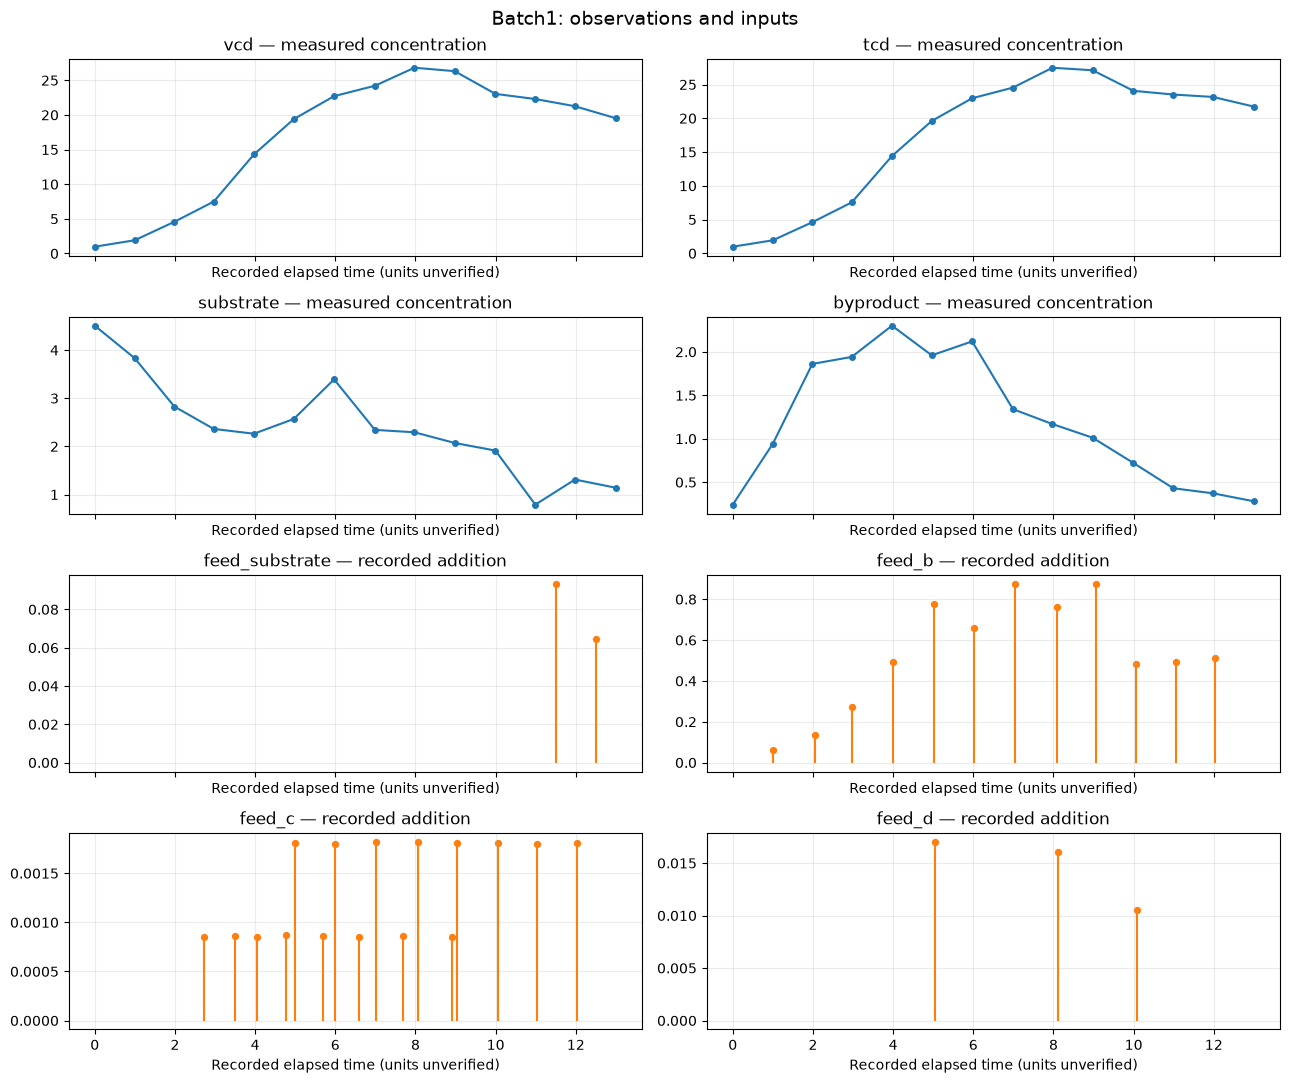

In [29]:
BATCH = "Batch1"
g = complete_obs.loc[complete_obs.batch_id.eq(BATCH)].sort_values("elapsed_time")
e = feed_events.loc[feed_events.batch_id.eq(BATCH)]
assert not g.empty, "Choose a complete batch for this plot."
fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True)
for ax, target in zip(axes[:2].flat, TARGETS):
    ax.plot(g.elapsed_time, g[target], "o-", markersize=4)
    ax.set_title(target + " — measured concentration")
for ax, feed in zip(axes[2:].flat, FEEDS):
    events = e.dropna(subset=[feed])
    ax.vlines(events.elapsed_time, 0, events[feed], color="tab:orange")
    ax.scatter(events.elapsed_time, events[feed], color="tab:orange", s=18)
    ax.set_title(feed + " — recorded addition")
for ax in axes.flat:
    ax.grid(alpha=.25)
    ax.set_xlabel("Recorded elapsed time (units unverified)")
fig.suptitle(BATCH + ": observations and inputs", fontsize=14)
fig.tight_layout()
plt.show()

### Pause here
Write answers in the blank cell below:
1. When does VCD reach its observed maximum? 27 at timepoint 8
2. Does byproduct rise forever, or turn downward? starts droping at timepoint 4 
3. Do substrate increases occur after feed events? yes we observe an increase right after bigger additions of feed c, a plateau at the max additions of feed b, and an other increase almost at the same time as the second addition of feed d and first addition of substrate feed

Question 3 suggests a timing relationship, not proof of feed composition or causality.

## 5. Check whether the same shapes occur across batches
Every thin line below is one complete batch. These are not averages. Look for common shapes and exceptions.

Do not interpret the apparent amount of data as thousands of independent cultures: there are only 49 complete runs.

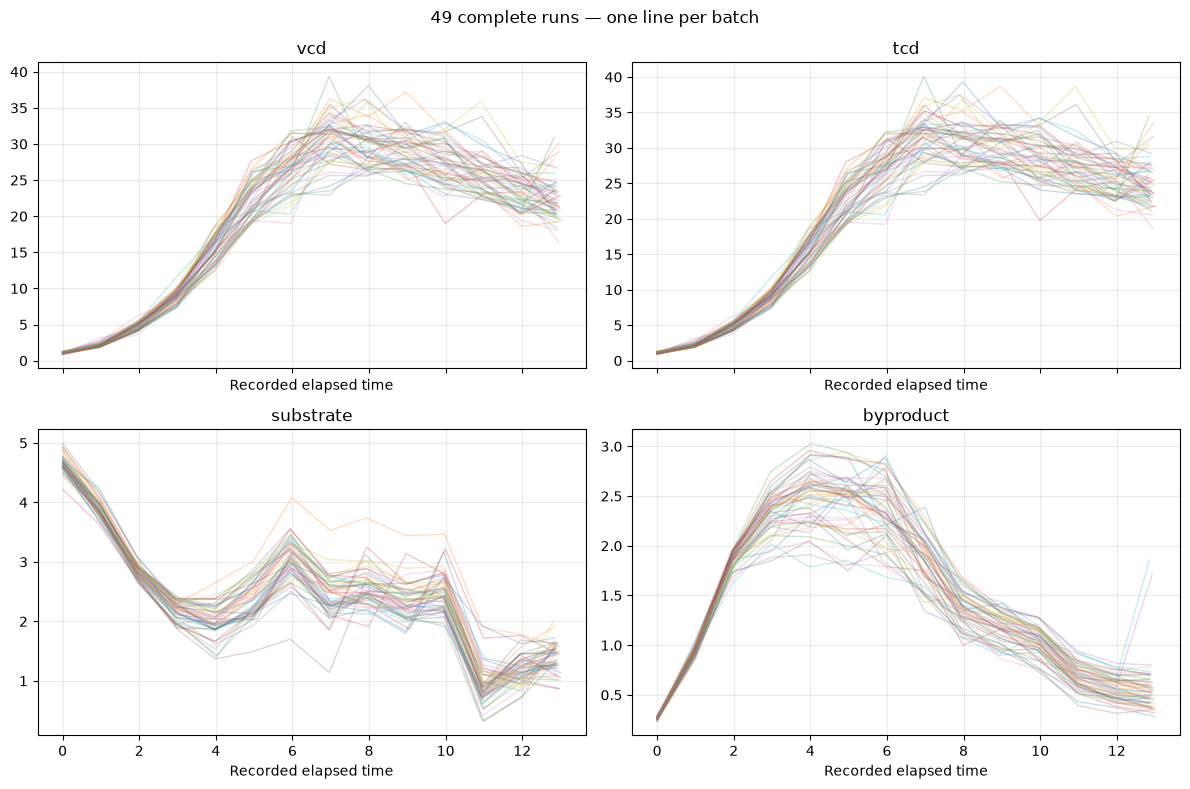

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for _, batch in complete_obs.groupby("batch_id"):
    batch = batch.sort_values("elapsed_time")
    for ax, target in zip(axes.flat, TARGETS):
        ax.plot(batch.elapsed_time, batch[target], alpha=.25, lw=1)
for ax, target in zip(axes.flat, TARGETS):
    ax.set_title(target)
    ax.set_xlabel("Recorded elapsed time")
    ax.grid(alpha=.25)
fig.suptitle("49 complete runs — one line per batch")
fig.tight_layout()
plt.show()

### Read the plots
Ask about shapes, not mechanisms yet. A rise then fall in byproduct is an observation. Calling it lactate consumption is a biological hypothesis requiring additional evidence.

## 6. Separate concentration from amount
Concentration means amount *per volume*. Adding liquid can reduce a concentration without removing material.

We calculate:
- `viability_pct = 100 × vcd / tcd`: the living fraction of counted cells.
- `dead_density = tcd - vcd`: a derived dead-cell density under the given counting definition.
- `byproduct_amount_proxy = byproduct × volume`.

The last quantity is proportional to amount if the units are compatible. Its label stays a proxy until units are verified.

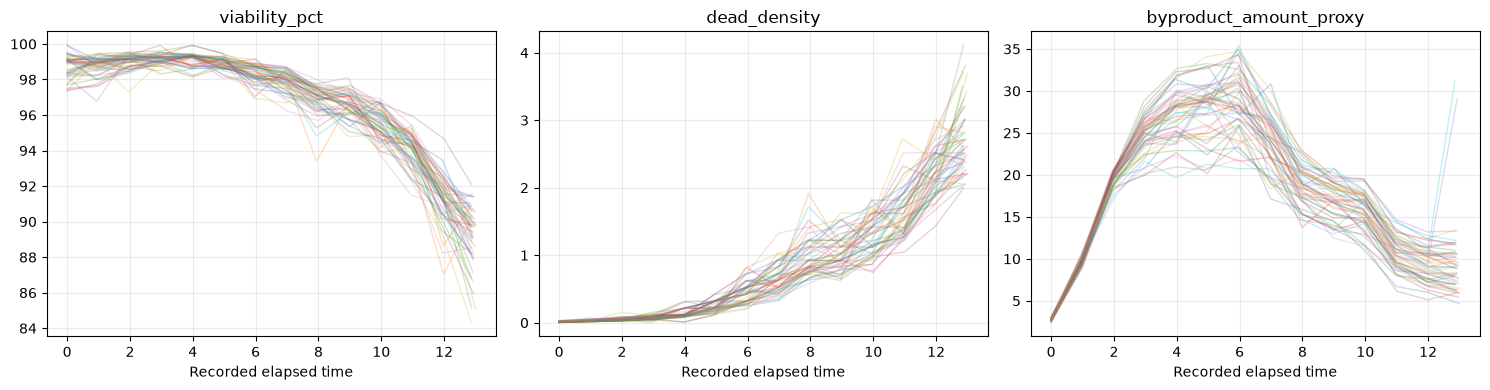

Runs ending below their maximum byproduct amount proxy: 49 / 49


In [31]:
physical = complete_obs.copy()
physical["viability_pct"] = 100 * physical.vcd / physical.tcd
physical["dead_density"] = physical.tcd - physical.vcd
physical["byproduct_amount_proxy"] = physical.byproduct * physical.volume
assert physical.dead_density.ge(0).all()

cols = ["viability_pct", "dead_density", "byproduct_amount_proxy"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for _, batch in physical.groupby("batch_id"):
    batch = batch.sort_values("elapsed_time")
    for ax, col in zip(axes, cols):
        ax.plot(batch.elapsed_time, batch[col], alpha=.25, lw=1)
for ax, col in zip(axes, cols):
    ax.set_title(col)
    ax.set_xlabel("Recorded elapsed time")
    ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

amount_declines = physical.groupby("batch_id")["byproduct_amount_proxy"].agg(
    ["max", "last"]
)
print("Runs ending below their maximum byproduct amount proxy:",
      int((amount_declines["last"] < amount_declines["max"]).sum()),
      "/", len(amount_declines))

### Read the result
A declining byproduct amount proxy means dilution alone is not the full explanation, assuming the units and measurements are consistent. Possible additional explanations include consumption, conversion, or removal. This plot does not identify which one.

#### assumption:
as the volume doesn't decrease, I would likely assume that the decrease is caused by consumption or conversion, rather than removal

## 7. Audit volume bookkeeping — keep this separate from biology
Working hypothesis ONLY: all feed numbers are added volumes in the same units as `volume`.

Then, if there were no removals or other effects:

`expected volume = initial volume + cumulative additions`

The residual below is recorded volume minus this simple expectation. A nonzero residual challenges the assumptions; it does not prove evaporation or sampling.

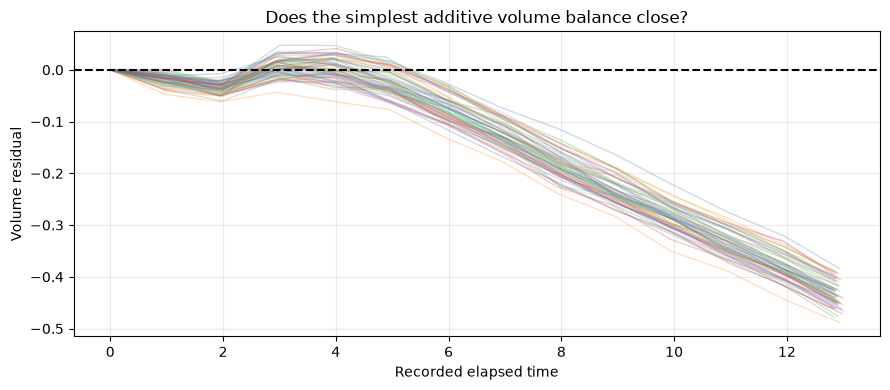

count    61.000000
mean     -0.434336
std       0.025243
min      -0.488495
25%      -0.451833
50%      -0.437547
75%      -0.417039
max      -0.383531


In [32]:
events = df.copy()
events["addition_total"] = events[FEEDS].fillna(0).sum(axis=1)
events["cumulative_addition"] = events.groupby("batch_id")["addition_total"].cumsum()
volumes = events.dropna(subset=["volume"]).copy()
volumes["initial_volume"] = volumes.groupby("batch_id")["volume"].transform("first")
volumes["expected_volume"] = volumes.initial_volume + volumes.cumulative_addition
volumes["volume_residual"] = volumes.volume - volumes.expected_volume

fig, ax = plt.subplots(figsize=(9, 4))
for _, batch in volumes.groupby("batch_id"):
    ax.plot(batch.elapsed_time, batch.volume_residual, alpha=.25, lw=1)
ax.axhline(0, color="black", linestyle="--")
ax.set(xlabel="Recorded elapsed time", ylabel="Volume residual",
       title="Does the simplest additive volume balance close?")
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()
print(volumes.groupby("batch_id")["volume_residual"].last().describe().to_string())

### Read the result
A systematic negative residual means recorded volume is below initial volume plus additions, under the stated hypothesis. Ask about feed units, withdrawals, and volume measurement conventions. Do not make biological rates compensate for unexplained physical bookkeeping.

## 8. Build cumulative feed features at observation times
We do not forward-fill individual additions. Instead, we sum additions up to each event, separately within each batch.

Because observation rows are already in the event table, no nearest-time merge is needed. These features are useful for later models. We do not train such a model yet.

In [33]:
cum_cols = ["cum_" + f for f in FEEDS]
events[cum_cols] = events[FEEDS].fillna(0).groupby(events.batch_id).cumsum()
feature_table = events.loc[events[TARGETS].notna().all(axis=1)].copy()
initial_table = observations.groupby("batch_id", sort=False).head(1)
initial_table = initial_table[["batch_id"] + TARGETS + ["volume"]].rename(
    columns={c: "initial_" + c for c in TARGETS + ["volume"]}
)
feature_table = feature_table.merge(initial_table, on="batch_id", validate="many_to_one")
print(feature_table.loc[feature_table.batch_id.eq(BATCH),
      ["elapsed_time", "volume"] + cum_cols].head(6).to_string(index=False))

 elapsed_time    volume  cum_feed_substrate  cum_feed_b  cum_feed_c  cum_feed_d
     0.000000 10.500750                 0.0    0.000000    0.000000         0.0
     0.996528 10.494285                 0.0    0.000000    0.000000         0.0
     1.984722 10.537027                 0.0    0.062214    0.000000         0.0
     2.967361 10.695897                 0.0    0.198313    0.000854         0.0
     3.970833 10.946566                 0.0    0.470207    0.001718         0.0
     4.963889 11.417555                 0.0    0.964163    0.003447         0.0


## 9. Make one honest prediction baseline
Question: **How well can we predict a new batch just by using typical trajectories from other batches?**

We hold out 10 entire complete batches using a fixed random seed. We never fit using their future biological measurements.

Baseline A: keep each held-out batch at its observed initial value.

Baseline B: interpolate each fitting batch onto a common time grid, average the curves, then predict that typical curve for held-out batches. Interpolation is used only to summarize measured FITTING trajectories. It never fills hidden validation labels.

This is a reference score, not a final model. It deliberately ignores feeds and volume. That makes it easy to understand and gives future models something concrete to beat. We score only times after the initial measurement.

In [34]:
rng = np.random.default_rng(42)
shuffled_ids = rng.permutation(np.array(complete_ids))
valid_ids = list(shuffled_ids[:10])
fit_ids = list(shuffled_ids[10:])
fit_obs = complete_obs.loc[complete_obs.batch_id.isin(fit_ids)].copy()
valid_obs = complete_obs.loc[complete_obs.batch_id.isin(valid_ids)].copy()
assert set(fit_ids).isdisjoint(valid_ids)

fit_first = fit_obs.groupby("batch_id").elapsed_time.min()
fit_last = fit_obs.groupby("batch_id").elapsed_time.max()
grid = np.linspace(fit_first.min(), fit_last.max(), 250)
typical_curves = {}
for target in TARGETS:
    curves = []
    for _, batch in fit_obs.groupby("batch_id"):
        batch = batch.sort_values("elapsed_time")
        curves.append(np.interp(grid, batch.elapsed_time, batch[target]))
    typical_curves[target] = np.mean(curves, axis=0)

scores = []
validation_predictions = valid_obs.copy()
first_times = valid_obs.groupby("batch_id").elapsed_time.transform("min")
future = valid_obs.elapsed_time > first_times
for target in TARGETS:
    validation_predictions["typical_" + target] = np.interp(
        valid_obs.elapsed_time, grid, typical_curves[target])
    validation_predictions["constant_" + target] = valid_obs.groupby(
        "batch_id")[target].transform("first")
    for baseline in ["constant", "typical"]:
        error = (validation_predictions.loc[future, baseline + "_" + target]
                 - valid_obs.loc[future, target])
        scores.append({"target": target, "baseline": baseline,
                       "MAE": error.abs().mean(),
                       "RMSE": np.sqrt((error**2).mean())})
scores = pd.DataFrame(scores)
print("Fitting batches:", len(fit_ids), "| Held-out batches:", len(valid_ids))
print(scores.round(4).to_string(index=False))
print("Do not compare raw RMSE across targets: their units and scales differ.")

Fitting batches: 39 | Held-out batches: 10
   target baseline     MAE    RMSE
      vcd constant 20.3378 22.6881
      vcd  typical  1.9981  2.8009
      tcd constant 21.2276 23.7045
      tcd  typical  2.0476  2.9106
substrate constant  2.4086  2.5424
substrate  typical  0.1977  0.2523
byproduct constant  1.1789  1.3764
byproduct  typical  0.1559  0.2144
Do not compare raw RMSE across targets: their units and scales differ.


## 10. Look at the prediction, not only the score
Solid line: actual held-out measurements. Dashed line: typical-trajectory prediction. Dotted line: unchanged initial value.

Change `EXAMPLE` to another entry in `valid_ids`. Some batches will be easier than others. A model that follows the broad shape can still miss peak timing or final viability.

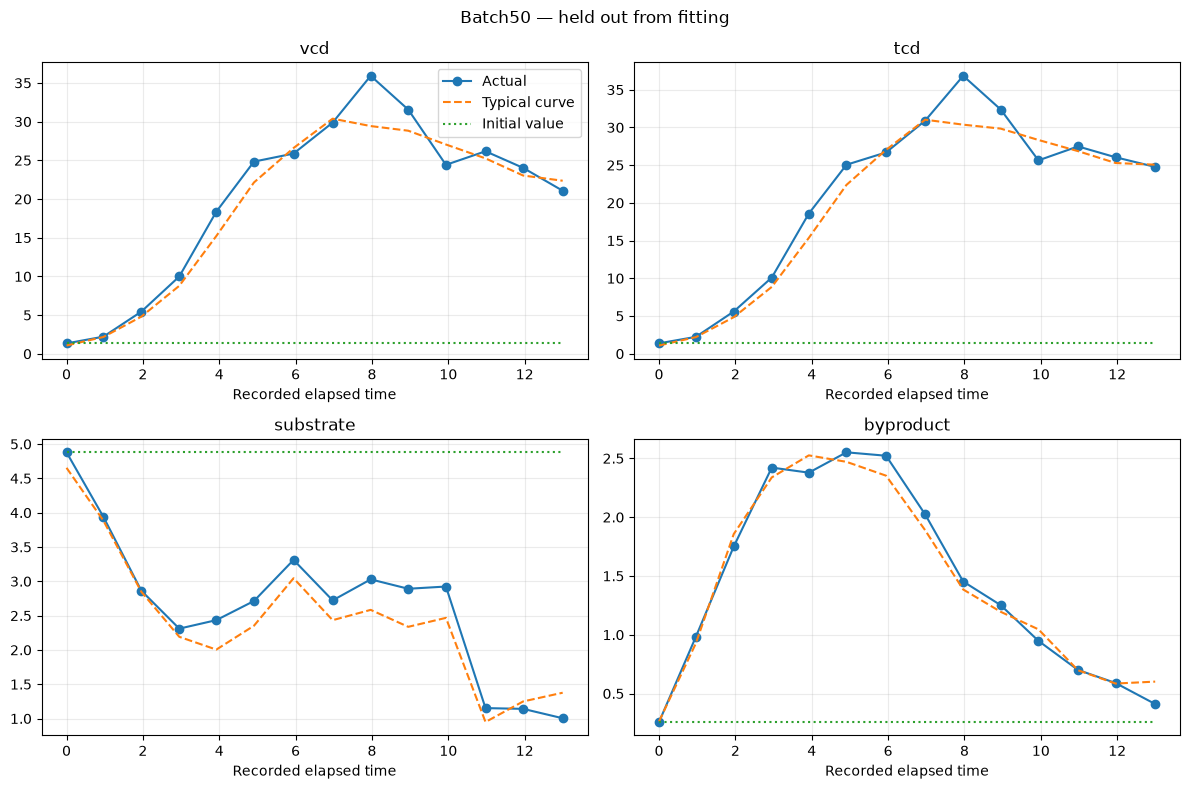

In [35]:
EXAMPLE = valid_ids[3]
batch = validation_predictions.loc[
    validation_predictions.batch_id.eq(EXAMPLE)
].sort_values("elapsed_time")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, target in zip(axes.flat, TARGETS):
    ax.plot(batch.elapsed_time, batch[target], "o-", label="Actual")
    ax.plot(batch.elapsed_time, batch["typical_" + target], "--", label="Typical curve")
    ax.plot(batch.elapsed_time, batch["constant_" + target], ":", label="Initial value")
    ax.set_title(target)
    ax.set_xlabel("Recorded elapsed time")
    ax.grid(alpha=.25)
axes.flat[0].legend()
fig.suptitle(EXAMPLE + " — held out from fitting")
fig.tight_layout()
plt.show()

## 11. Save reusable outputs
These are analysis files, not a competition submission. This cell exports the feature table, baseline scores, held-out predictions, and split assignments. All analysis choices above are explicit and reproducible.

In [36]:
OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
feature_table.to_csv(OUTPUT_DIR / "measurement_features.csv", index=False)
scores.to_csv(OUTPUT_DIR / "baseline_scores.csv", index=False)
validation_predictions.to_csv(OUTPUT_DIR / "held_out_predictions.csv", index=False)
pd.DataFrame({"batch_id": fit_ids + valid_ids,
              "split": ["fit"] * len(fit_ids) + ["validation"] * len(valid_ids)}).to_csv(
    OUTPUT_DIR / "batch_split.csv", index=False)
print("Saved analysis tables to", OUTPUT_DIR)

Saved analysis tables to analysis_outputs


## 12. Decide the next experiment — do not do everything at once

You now have:
1. Cleanly separated observations, feeds, and requested predictions.
2. A visual understanding of individual and population trajectories.
3. A physical diagnostic that flags unresolved volume assumptions.
4. A simple held-out-batch reference score.

**Recommended next experiment:** fit a modest tabular regressor using elapsed time, initial conditions, cumulative feeds, and volume if allowed. Reuse exactly the same held-out batches and compare against the typical-trajectory baseline. If it helps, evaluate across several batch-level splits before making a strong claim.

Only then consider event-driven ODE modeling. Do not fit an accumulating-only byproduct model without explaining the observed decline.

### My conclusions
- Observations supported by plots:
- Hypotheses still unverified:
- Biggest baseline failure:
- Units / task questions for organizers:
- Next model and success criterion:

### Provenance
This notebook analyzes the supplied `bioreaction_remaining.csv`. It does not infer organism identity, feed chemistry, official units, or the evaluation contract from numerical patterns. The fixed holdout is a first experiment, not a final unbiased estimate after repeated model tuning.
